# Self-Organizing Maps: Cell States and Gene Modules

A self-organizing map is a small, fixed grid of nodes — say 20 × 20 = 400 of them. Each node owns one
**codebook vector**: a prototype living in exactly the same space as the cells, so if you train on 50
principal components, every node holds 50 numbers. Assignment is then trivial: a cell belongs to its
**best-matching unit** (BMU), the node whose codebook is nearest in Euclidean distance. That much is
just vector quantization, and k-means would do it.

Training is what makes the grid a *map*. Each time a cell is presented, its BMU is pulled toward it —
**and so are that node's neighbours on the grid**, by an amount that falls off with grid distance. The
neighbourhood radius starts wide and anneals to a single node, and the learning rate anneals to zero.
So early training drags whole regions of the grid around at once, and late training only fine-tunes
individual nodes. The consequence is the property everything below depends on: **at the end, nodes
that are close on the grid hold cells that are similar in expression.** The grid has unfolded over the
data manifold like an elastic net, and you can read it as a 2-D map of that manifold.

Single-cell analysis uses SOMs through the FlowSOM recipe (Van Gassen et al. 2015, *Cytometry A*;
protocol: Quintelier et al. 2021, *Nat Protoc*), which is four steps: **scale** the features,
**overcluster** onto a grid of hundreds of nodes, **meta-cluster** the node codebooks into a handful
of reported populations with Ward linkage, and **measure** whether the map is any good. The grid is
the quantization; the metacluster is the cluster. Step four is not optional and this notebook treats
it as the main event.

Why reach for a SOM when Leiden already exists?

- **The map is a diagnostic.** A fixed grid supports instruments graph clustering has no analogue for
  — the U-matrix, the hit map, component planes — so you can inspect whether the representation is
  trustworthy *before* believing the labels it produces.
- **Rare states get their own nodes.** Overclustering deliberately leaves room for small populations
  instead of absorbing them into a large cluster's boundary.
- **Per-marker landscapes.** A component plane shows where in the map a single gene lives, which is
  how FlowSOM users read cell identity off a map directly.

Requires the `minisom` extra: `uv add "astrolabe[som]"`.

**Subcellular transcript localization used to live here.** It moved to
`14_subcellular_localization.ipynb` and stopped being SOM-based, because a SOM binning 2-D positions
was doing no work that a named compartment could not do better — see that notebook's introduction for
what went wrong and how it was fixed.

## 1. Setup

The standard pipeline from `01_core_workflow.ipynb`. Leiden is here as the **comparator**: the SOM
sections cluster the same PCA space by a different principle, and section 2 measures how much they
agree rather than asserting it.

In [1]:
import logging
logging.basicConfig(level=logging.INFO)

import numpy as np
import minisom  # noqa: F401  -- this notebook requires the [som] extra
import astrolabe as ab

mdata = ab.datasets.xenium()
ab.pipeline.filter_xenium(mdata)

ab.pp.normalize_total(mdata)
ab.pp.log1p(mdata)
ab.pp.highly_variable_genes(mdata, n_top_genes=2000)
ab.tl.pca(mdata)
ab.tl.transcriptional_neighbors(mdata)
ab.tl.cluster(mdata, resolution=0.5)

xen = mdata['xenium']
print(f"{xen.n_obs} cells x {xen.n_vars} genes, "
      f"{xen.obs['leiden'].nunique()} Leiden clusters")

INFO:astrolabe.pl._theme:Registered bundled Inter font files with matplotlib


INFO:astrolabe.pl._theme:astrolabe plot theme set to 'light'


INFO:astrolabe.io._xenium:Reading Xenium run 'outs' from C:\Users\Austin\PycharmProjects\astrolabe\.astrolabe_cache\datasets\xenium_ffpe\outs


C:\Users\Austin\PycharmProjects\astrolabe\.venv\Lib\site-packages\anndata\utils.py:362: ExperimentalFeatureWarning: Support for Awkward Arrays is currently experimental. Behavior may change in the future. Please report any issues you may encounter!
  warnings.warn(msg, category, stacklevel=stacklevel)


INFO:astrolabe.io._xenium:Attached morphology image from morphology.ome.tif: 8 level(s), shape=(11, 17098, 51187), pixel_size=0.2125 µm


INFO:astrolabe.io._xenium:Loaded 162254 cells × 541 features (164 control probes)


INFO:astrolabe.io._he:Reading H&E 'he_image' from C:\Users\Austin\PycharmProjects\astrolabe\.astrolabe_cache\datasets\xenium_ffpe\outs\he_image.ome.tif


INFO:astrolabe.io._he:Loaded H&E: pixel_size=0.2738 µm, 6 pyramid level(s), shape=(45087, 11580, 3), stains=separated


INFO:astrolabe.io._xenium:Attached H&E image from C:\Users\Austin\PycharmProjects\astrolabe\.astrolabe_cache\datasets\xenium_ffpe\outs\he_image.ome.tif (aligned)


INFO:astrolabe.io._xenium:Streaming transcripts from C:\Users\Austin\PycharmProjects\astrolabe\.astrolabe_cache\datasets\xenium_ffpe\outs\transcripts.parquet


INFO:astrolabe.io._xenium:Loaded 10607572 transcript detections


INFO:astrolabe.io._annotations:Reading annotations from C:\Users\Austin\PycharmProjects\astrolabe\.astrolabe_cache\datasets\xenium_ffpe\outs\annotation.geojson


INFO:astrolabe.io._annotations:Loaded 11 annotation region(s)


INFO:astrolabe.pipeline:filter_xenium: 162254 cells × 541 genes


INFO:astrolabe.pipeline:  calculate_xenium_qc_metrics


INFO:astrolabe.pp._qc:flag_controls: 164 / 541 features flagged as controls; obs['pct_counts_control'] computed (median 0.00%, max 50.00%)


INFO:astrolabe.pipeline:filter_cells: 162254 cells × 541 genes


INFO:astrolabe.pp._qc:calculate_qc_metrics: percent_top values [500] exceed the 377-feature panel and were skipped.


INFO:astrolabe.pp._qc:calculate_noise_floor: threshold = 0.0001276 mean counts/cell (quantile 0.95 of 164 controls); 0 / 377 genes at or below it -> var['below_noise_floor']


INFO:astrolabe.pp._qc:filter_cells: removing 7785 / 162254 cells


INFO:astrolabe.pp._qc:  synced uns['transcripts']: 10607572 -> 10565019 rows (dropped filtered-out cells)


INFO:astrolabe.pipeline:  [filter_cells] 162254 → 154469 cells  (removed 7785, 4.8%)


INFO:astrolabe.pp._qc:filter_genes: removing 0 / 541 features


INFO:astrolabe.pipeline:  [filter_genes] 541 → 541 genes  (removed 0, 0.0%)


INFO:astrolabe.pp._qc:filter_isolated: removing 93 / 154469 cells (k=5, max_neighbor=60 um, min_neighbor=50 um)


INFO:astrolabe.pp._qc:  synced uns['transcripts']: 10565019 -> 10560229 rows (dropped filtered-out cells)


INFO:astrolabe.pipeline:  [filter_isolation] 154469 → 154376 cells  (removed 93, 0.1%)


INFO:astrolabe.pipeline:filter_cells: done — 154376 cells × 541 genes


INFO:astrolabe.pp._qc:filter_genes: removing 164 / 541 features


INFO:astrolabe.pp._qc:  synced uns['transcripts']: 10560229 -> 10558164 rows (dropped filtered-out genes)


INFO:astrolabe.pipeline:  [remove_controls] 541 → 377 genes  (removed 164, 30.3%)


INFO:astrolabe.pipeline:filter_xenium: done — 154376 cells × 377 genes


INFO:astrolabe.tl._graph:transcriptional_neighbors: 154376 cells -> uns['neighbors']


INFO:astrolabe.tl._cluster:cluster (leiden, res=0.50): 10 clusters


154376 cells x 377 genes, 10 Leiden clusters


## 2. Cell-state clustering

Two knobs, answering different questions.

**Grid size** (`x`, `y`) is a *resolution* knob, not a cluster count. Nodes are bins on the expression
continuum; you want enough of them to overcluster. The library's default follows the classic
`5·sqrt(n)`-nodes heuristic, which for 154k cells gives about 45 × 45 = 2025 nodes. This notebook
uses **20 × 20 = 400** instead — still a 385-fold overclustering relative to the 15 reported
populations, and small enough that the map figures below stay legible at a printed size. Nothing
about the analysis needs the smaller grid; it is a figure-readability choice, and worth naming as one.

**`n_metaclusters`** is the number of reported populations — the Ward cut through the 400 codebook
vectors. This is the number comparable to a Leiden result, and section 2.3 asks whether it is
defensible.

One subtlety the log line exposes: `scale`. FlowSOM z-scores its input, and `tl.som` does too **when
training on raw genes** — otherwise Euclidean matching is dominated by whichever gene is most
abundant. But it deliberately leaves an embedding like `X_pca` alone. The reason is not that whitening
disagrees with Leiden (tuning one clustering to match another and then citing the match proves
nothing); it is that whitening rescales every component to unit variance, which hands PC50's noise the
same influence over BMU assignment as PC1's signal — amplifying exactly the components that PC
truncation exists to discard. Leaving the embedding unscaled also keeps the SOM in the same metric as
`sc.pp.neighbors` and UMAP, so all three are measuring the same geometry.

In [2]:
ab.tl.som(mdata, use_rep='X_pca', x=20, y=20, n_metaclusters=15,
          n_epochs=10, seed=42)

params = xen.uns['som']['params']
print(f"grid {params['x']}x{params['y']}, "
      f"QE={params['quantization_error']:.3f}, "
      f"TE={params['topographic_error']:.3f}")
print(xen.obs['som_cluster'].value_counts().sort_index())

INFO:astrolabe.tl._som:som: training 20×20 grid on 154376 cells (50 features, 10 epochs, sigma=5.00→1, scale=False)


INFO:astrolabe.tl._som:som: done — 15 metaclusters from 400 nodes (QE=2.399, TE=0.050) → obs['som_cluster'], obs['som_node'], uns['som']


grid 20x20, QE=2.399, TE=0.050
som_cluster
0     22424
1     13200
2      5742
3      8016
4     16835
5     13255
6     19148
7     11694
8      6576
9      6264
10     7327
11     8066
12     3765
13     2661
14     9403
Name: count, dtype: int64


Two labels at two granularities. `obs['som_node']` is the raw BMU — 400 bins, a discretized
embedding, not a set of populations. `obs['som_cluster']` is the Ward metacluster, and that is the
cluster label.

The two stored numbers are how you judge the map before trusting either:

- **Topographic error (TE)** — the fraction of cells whose two best-matching nodes are *not*
  grid-adjacent. This is the assumption every map figure below rests on. A few percent means grid
  adjacency reflects real expression adjacency. Large TE means adjacency on the map is meaningless,
  and no amount of staring at the U-matrix will fix it: retrain with more epochs or a smaller grid.
- **Quantization error (QE)** — the mean distance from each cell to its BMU, i.e. residual rounding
  error from replacing cells with prototypes. Its absolute value depends on the feature space, so
  compare it across runs on the *same* data (grid sizes, epoch counts) and never across datasets.

### 2.1 Is the map trustworthy?

In [3]:
(
    ab.pl.som_umatrix(mdata)
    | ab.pl.som_hits(mdata)
    | ab.pl.som_quality_plot(mdata)
).show()

The three panels answer three different questions, and they are meant to be read together.

- **U-matrix** (Ultsch 1990): each node coloured by the mean codebook distance to its grid
  neighbours. Dark basins are coherent regions of expression space; bright ridges are the boundaries
  between them, and the Ward metaclusters should largely respect those ridges. The values are in the
  training space's own units — deliberately **not** min-max normalized, which is what minisom's own
  `distance_map()` returns. Normalizing forces the maximum to exactly 1.0 whatever the data, so a
  collapsed, over-smoothed codebook renders identically to a well-separated one. Real units keep that
  difference visible.
- **Hit map**: cells per node. Uneven is expected and fine — dense nodes are common states, sparse
  ones rare or transitional. What you are looking for is pathology at either extreme: *many empty
  nodes* means the grid is oversized for the data, and *one node holding a large share of all cells*
  means it is undersized.
- **Topology plot**: codebook distance against grid distance. The headline number is the **local**
  Spearman correlation, over pairs within a few grid steps, and the global value is shown next to it
  for contrast. That distinction matters: topology preservation is a claim about *neighbourhoods*, and
  a correlation over all pairs is dominated by the global trend — even a badly folded map scores 0.7
  or higher simply because opposite corners of the grid really are far apart. A large gap between
  global and local is the signature of folding. **Trustworthiness** and **continuity** (Venna & Kaski
  2001) put numbers on the two ways a neighbourhood can be wrong: trustworthiness falls when nodes are
  grid-neighbours but not codebook-neighbours — false adjacency, the failure that makes a map figure
  lie — and continuity falls when codebook-neighbours get torn apart on the grid.

### 2.2 SOM against Leiden, measured

Both partition the same PCA manifold, by different principles: Ward linkage on prototype vectors
versus modularity on a KNN graph. Two panels of coloured dots side by side cannot tell you whether
they agree, so here are the numbers.

**Matched `k` first.** The adjusted Rand index penalizes a mismatch in cluster *count*, so comparing
15 SOM metaclusters against however many clusters `resolution=0.5` happened to give would confound
"different method" with "different granularity". Tuning Leiden's resolution to return the same count
makes the comparison about the method.

In [4]:
from sklearn.metrics import adjusted_rand_score, adjusted_mutual_info_score

target = xen.obs['som_cluster'].nunique()

# bisect the Leiden resolution until it returns `target` clusters
lo, hi = 0.1, 3.0
for _ in range(18):
    mid = (lo + hi) / 2
    ab.tl.cluster(mdata, resolution=mid, key_added='leiden_matched')
    n = xen.obs['leiden_matched'].nunique()
    if n == target:
        break
    lo, hi = (mid, hi) if n < target else (lo, mid)

som_lab = xen.obs['som_cluster'].astype(str)
print(f"SOM metaclusters: {target}   Leiden at resolution {mid:.3f}: {n}")
for name, col in (('leiden (res=0.5)', 'leiden'), ('leiden (matched k)', 'leiden_matched')):
    print(f"  {name:<20s} ARI {adjusted_rand_score(som_lab, xen.obs[col]):.3f}"
          f"   AMI {adjusted_mutual_info_score(som_lab, xen.obs[col]):.3f}")

INFO:astrolabe.tl._cluster:cluster (leiden, res=1.55): 18 clusters


INFO:astrolabe.tl._cluster:cluster (leiden, res=0.83): 11 clusters


INFO:astrolabe.tl._cluster:cluster (leiden, res=1.19): 15 clusters


SOM metaclusters: 15   Leiden at resolution 1.188: 15


  leiden (res=0.5)     ARI 0.447   AMI 0.629


  leiden (matched k)   ARI 0.478   AMI 0.635


An ARI in this range is the normal outcome, and the interesting question is not the number but
whether it is *low*. Two clusterings of a genuinely continuous manifold will disagree wherever the
manifold has no gap to cut at, and neither is wrong there. The referee has to be something external
to both.

Three external criteria, none of which privileges either method:

- **Expression-space silhouette** — do the labels describe compact, separated groups in the space
  both methods were given?
- **Spatial coherence** — the fraction of spatial-graph edges joining cells with the same label.
  Neither method is told any coordinates, so agreement with tissue architecture is independent
  evidence. (This is the same statistic `tl.banksy_sweep` reports as `neighbor_agreement`.)
- **Marker coherence** — how many clusters have at least one convincingly differential gene.

In [5]:
from sklearn.metrics import silhouette_score

ab.tl.spatial_neighbors(mdata, n_neighbors=6)
conn = xen.obsp[xen.uns['spatial_neighbors']['connectivities_key']].tocoo()
edge = conn.row < conn.col  # each undirected edge once

rng = np.random.default_rng(0)
sub = rng.choice(xen.n_obs, 20_000, replace=False)  # silhouette is O(n^2)
X = xen.obsm['X_pca'][sub]

rows = []
for name, col in (('SOM metacluster', 'som_cluster'),
                  ('Leiden (matched k)', 'leiden_matched')):
    lab = xen.obs[col].astype(str).to_numpy()
    sil = silhouette_score(X, lab[sub])
    same = float((lab[conn.row[edge]] == lab[conn.col[edge]]).mean())
    ab.tl.rank_genes_groups(mdata, groupby=col, key_added=f'rgg_{col}')
    rg = xen.uns[f'rgg_{col}']
    n_ok = sum(
        bool((np.asarray(rg['pvals_adj'][g]) < 0.01).any()
             and (np.asarray(rg['logfoldchanges'][g]) > 1).any())
        for g in rg['names'].dtype.names
    )
    rows.append((name, sil, same, n_ok, len(rg['names'].dtype.names)))

print(f"{'':<20s} {'silhouette':>11s} {'spatial coherence':>18s} {'clusters w/ marker':>20s}")
for name, sil, same, n_ok, n_tot in rows:
    print(f"{name:<20s} {sil:>11.3f} {same:>18.3f} {n_ok:>15d}/{n_tot}")

INFO:astrolabe.tl._graph:spatial_neighbors: 154376 cells, 1060234 edges (mean degree 6.9) [generic]


... storing 'feature_type' as categorical


... storing 'genome' as categorical


                      silhouette  spatial coherence   clusters w/ marker
SOM metacluster            0.049              0.354              15/15
Leiden (matched k)         0.063              0.413              15/15


Read these as a set. If the two methods score similarly on all three, the ARI between them is
measuring resolution limits rather than one method being right — which is the usual outcome on a
continuous manifold, and a more useful conclusion than declaring a winner. A method that wins on
silhouette while losing badly on spatial coherence is carving the expression space cleanly along
something that has no tissue correlate, which is worth knowing before building on it.

### 2.3 Does the map support 15 clusters?

`n_metaclusters=15` has been an assertion so far. `tl.som_stability` turns it into a measurement, two
ways.

**Reproducibility.** Retrain the SOM under different random seeds, cut each at every `k`, and compute
the mean pairwise adjusted Rand index between runs. Labels that do not survive a reseed are not a
result.

Expect this curve to **fall** with `k` and then flatten, and do not read that as a defect: cutting a
codebook into more pieces necessarily puts more boundaries in places the data does not fix, so a
two-way split is always more reproducible than a twenty-way one. The maximum therefore sits at the
smallest `k` you tested and tells you nothing. The two numbers that do mean something are the **ARI at
the `k` you intend to report** — printed below and ringed on the figure — and where the curve stops
changing, beyond which extra clusters buy nothing stable.

**Merge cost.** The Ward merge heights of the codebook. A pronounced jump means the merge below it
fused genuinely distinct prototypes, so the count just above it is a natural stopping point. A smooth
curve means the codebook is a continuum and no `k` is privileged — which is itself worth knowing
before quoting one.

Taken together these usually say something less tidy than "k = N is correct": that the broad
territories are stable across seeds while the fine boundaries between them are not. That is a real
property of a continuous expression manifold, and the useful response is to report the coarse structure
with confidence and treat the fine partition as provisional — not to hunt for a `k` at which the
instability disappears.

In [6]:
stab = ab.tl.som_stability(mdata, k_range=range(2, 31), n_seeds=3, seed=100)

st = xen.uns['som_stability']
print(f"ARI at the reported k={st['reference_k']}: {st['ari_at_reference_k']:.3f}")
print(f"curve is flat from k={st['flat_from']} to k={st['flat_to']} "
      f"(successive change < {st['plateau_tol']})")
print()
print(stab.set_index('k').round(3).T.to_string())

INFO:astrolabe.tl._som:som_stability: 3 seeded 20×20 run(s) on 50000 cells, k in [2, 30]


INFO:astrolabe.tl._som:som_stability: ARI at the reported k=15 is 0.549; the curve is flat (successive change < 0.05) from k=9 to k=30; ARI runs 0.879 at k=2 down to 0.437 at k=30 -> uns['som_stability']


ARI at the reported k=15: 0.549
curve is flat from k=9 to k=30 (successive change < 0.05)

k            2      3      4      5      6      7      8      9      10     11     12     13     14     15     16     17     18     19     20     21     22     23     24     25     26     27     28     29     30
mean_ari  0.879  0.794  0.685  0.577  0.580  0.611  0.640  0.574  0.555  0.527  0.535  0.530  0.554  0.549  0.530  0.516  0.518  0.519  0.523  0.503  0.497  0.501  0.511  0.516  0.513  0.507  0.495  0.465  0.437
sd_ari    0.028  0.046  0.072  0.085  0.092  0.064  0.074  0.060  0.053  0.034  0.035  0.025  0.018  0.023  0.027  0.041  0.035  0.021  0.020  0.030  0.024  0.029  0.028  0.029  0.033  0.035  0.033  0.012  0.008


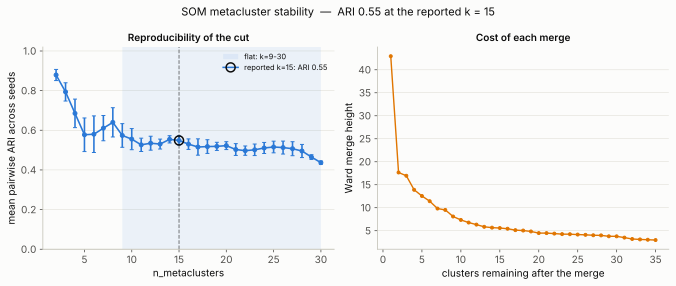

In [7]:
ab.pl.som_stability_plot(mdata).show()

### On the tissue

Putting the metacluster back into space. The rectangle marks a 600 µm window — a section this size
(10.8 × 3.5 mm) needs a box you can actually see, so the annotation and the crop are two panels rather
than one overloaded figure.

In [8]:
coords = xen.obsm['spatial']
cx = float(np.median(coords[:, 0]))
cy = float(np.median(coords[:, 1]))
context_rect = ab.pl.rectangle((cx - 300, cy - 300), 600.0, 600.0)
context = ab.pp.crop(mdata, context_rect, inplace=False)

(
    (ab.pl.points(mdata, color='som_cluster', title='SOM metaclusters, whole section')
     + ab.pl.annotation(context_rect))
    | ab.pl.points(context, color='som_cluster', title='600 µm window')
    | ab.pl.points(context, color='leiden_matched', title='Leiden (matched k)')
).show()

INFO:astrolabe.pp._transform:crop: xenium: keeping 3675 / 154376 cells inside region.


Zoomed in, the disagreements become legible: the two methods draw the same territories but place the
boundary cells differently, which is exactly where a continuous manifold has no gap to cut at.

## 3. Component planes

The **component plane** is FlowSOM's canonical per-marker readout. The trained codebook holds one
value per feature per node, so slicing out a single feature paints its landscape across the map: which
territory is "high EPCAM", which is "high PTPRC", and whether two markers occupy the same territory
(co-expression) or disjoint ones (mutually exclusive programs).

This needs the codebook to live in **gene** space, so it trains a second SOM directly on expression
(`use_rep=None`) — and per the scaling rule above, raw features are auto z-scored, which also makes
plane amplitudes comparable between genes rather than dominated by each gene's abundance. The 10 × 10
grid is FlowSOM's own default.

**This is a separate, independently trained map.** Its nodes have nothing to do with section 2's, and
its metaclusters are not section 2's clusters. Read the planes against *this* map's U-matrix, which is
why they are drawn together.

In [9]:
ab.tl.som(mdata, use_rep=None, x=10, y=10, n_metaclusters=15,
          key_added='som_expr', seed=42)

(
    ab.pl.som_umatrix(mdata, key='som_expr')
    | ab.pl.som_component_plane(mdata, 'EPCAM', key='som_expr')
    | ab.pl.som_component_plane(mdata, 'PTPRC', key='som_expr')
).show()

INFO:astrolabe.tl._som:som: training 10×10 grid on 154376 cells (377 features, 10 epochs, sigma=2.50→1, scale=True)


INFO:astrolabe.tl._som:som: done — 15 metaclusters from 100 nodes (QE=17.454, TE=0.040) → obs['som_expr_cluster'], obs['som_expr_node'], uns['som_expr']


Read the planes against the U-matrix on the left. A marker whose high-weight territory sits inside one
U-matrix basin *defines* that basin's identity. Two markers with overlapping territories are
co-expressed in the same states; complementary territories — an epithelial marker against the
pan-immune PTPRC — partition the map into lineages. Because the weights are z-scored, "high" means
high *for that gene*, so the colour scales are comparable between planes.

## 4. Gene co-expression modules

The same machinery, transposed: genes become the observations, each represented by its expression
profile across cells. Two preprocessing steps, each defined by the failure it prevents.

**Z-score per gene, then reduce to principal components.** For z-scored vectors,
`||a − b||² = 2n(1 − corr(a, b))`, so Euclidean distance in that space *is* correlation distance.
Skip the z-scoring and Euclidean distance mostly measures overall expression magnitude, which yields
one giant "abundant genes" module plus noise. One caveat the library reports rather than glosses: the
identity is exact *before* the PCA truncation. Projecting onto the top 50 of up to 376 components
shortens every distance by the discarded residual, so the training metric is correlation distance
*restricted to the leading components*. That is a deliberate denoising choice, and
`params['pca_variance_retained']` and `params['distance_fidelity']` say how good the approximation
actually was on your data.

**Score cells with `sc.tl.score_genes`**, not a raw mean of member genes. A raw mean would just
re-measure the magnitude the clustering was built from; the background-corrected score subtracts a
matched-expression control set.

Precedent for the SOM-for-gene-programs route: SOMDE (Hao et al. 2021), and the oposSOM
expression-portrait lineage. It complements `tl.spatial_gene_modules` (notebook 06), which groups
genes by *spatial* co-variation instead — programs found by both routes are the most robust.

In [10]:
gene_df = ab.tl.som_gene_modules(mdata, n_modules=10, seed=42)
print(xen.uns['som_gene_modules']['module_coherence'].round(3).to_string(index=False))

INFO:astrolabe.tl._som:som_gene_modules: training 10×10 grid on 377 genes (z-scored, 50 dims, 50 epochs, sigma=2.50→1) → 10 modules


INFO:astrolabe.tl._som:som_gene_modules: 377 genes → 9 coherent module(s) + 133 unassigned (QE=145.347, TE=0.011; PCA retained 26% of variance, distance fidelity 0.47) → var['som_gene_module'], var['som_gene_module_kme'], uns['som_gene_modules']['module_coherence']


    module  metacluster  n_genes  mean_within_r  mean_between_r  eigengene_var_explained  coherent
        M0            0       44          0.094          -0.007                    0.133      True
        M1            1       31          0.100          -0.008                    0.150      True
        M2            2       27          0.080          -0.009                    0.127      True
unassigned            3      133          0.002          -0.001                    0.013     False
        M4            4       35          0.083          -0.005                    0.134      True
        M5            5       23          0.054          -0.002                    0.115      True
        M6            6       14          0.171          -0.003                    0.265      True
        M7            7       25          0.166          -0.010                    0.219      True
        M8            8       24          0.059          -0.002                    0.128      True
        M9

### Reading the coherence table before reading the modules

This table is the point of the section. Module *size* tells you nothing about whether a module is a
program:

- **`mean_within_r`** — mean pairwise correlation among members. A co-expression module has members
  that correlate; a value near zero means the "module" is a bag of genes that correlate with nothing,
  including each other.
- **`mean_between_r`** — the same against non-members, as the reference for the above.
- **`eigengene_var_explained`** — the share of member variance captured by PC1 of their profiles. A
  real program is close to one-dimensional; below roughly 0.25 it is not a program.
- **`coherent`** — whether the module cleared `min_coherence`. Modules that fail are relabelled
  **`unassigned`** and excluded from scoring.

That relabelling is deliberate, and it is why one module can swallow a large share of the panel
without that being reported as a discovery. Per-gene z-scoring puts genes whose profile is Poisson
noise on equal footing with real programs; having no correlation with anything, they carry almost no
variance along the leading components, collapse toward the origin after truncation, and Ward hands
the whole blob a single cluster. That cluster is a **residual class**, not a module — WGCNA's grey
module (Langfelder & Horvath 2008) — and on a targeted panel where most genes are lineage markers
expressed in a minority of cells, it can legitimately be large. Naming it `M0` and printing its gene
list would be reporting the panel's noise floor as a finding.

### Which genes define a module?

`var['som_gene_module_kme']` holds each gene's correlation with its own module's eigengene — WGCNA's
kME. The high-|kME| members are the hub genes worth naming a module by. Sorting by kME rather than
alphabetically matters more than it sounds: the alphabetically-first members of a module are a random
sample of it, so a printed alphabetical list looks like evidence and contains none.

In [11]:
names = xen.uns['som_gene_modules']['module_names']
for m in names:
    sub = gene_df[gene_df['module'] == m]
    sub = sub.reindex(sub['kme'].abs().sort_values(ascending=False).index)
    hubs = ", ".join(f"{r.gene} ({r.kme:+.2f})" for r in sub.head(6).itertuples())
    print(f"{m:<4s} n={len(sub):>3d}   {hubs}")

n_un = int((gene_df['module'] == 'unassigned').sum())
print(f"\nunassigned: {n_un} / {len(gene_df)} genes "
      f"({100 * n_un / len(gene_df):.0f}%)")
p = xen.uns['som_gene_modules']['params']
print(f"PCA retained {p['pca_variance_retained']:.1%} of gene-profile variance; "
      f"distance fidelity {p['distance_fidelity']:.2f}")

M0   n= 44   MRC1 (+0.67), MS4A6A (+0.63), CD163 (+0.59), AIF1 (+0.56), MS4A4A (+0.56), VSIG4 (+0.51)
M1   n= 31   LTBP2 (+0.68), COL5A2 (+0.59), PDGFRB (+0.58), PDGFRA (+0.56), MYLK (+0.55), FBN1 (+0.55)
M2   n= 27   KRT7 (+0.66), GPRC5A (+0.63), MYC (+0.55), STEAP4 (+0.53), MET (+0.50), COL17A1 (+0.42)
M4   n= 35   VWF (+0.71), CLEC14A (+0.66), ADGRL4 (+0.61), ECSCR (+0.55), EGFL7 (+0.54), PECAM1 (+0.53)
M5   n= 23   CD79A (+0.68), MS4A1 (+0.57), MZB1 (+0.52), TENT5C (+0.48), BANK1 (+0.47), CD19 (+0.45)
M6   n= 14   C20orf85 (+0.81), C1orf194 (+0.76), TSPAN19 (+0.69), SNTN (+0.63), DNAAF1 (+0.62), C6orf118 (+0.61)
M7   n= 25   TRAC (+0.72), IL7R (+0.65), CXCR4 (+0.65), PTPRC (+0.64), CD2 (+0.64), CD3E (+0.62)
M8   n= 24   MS4A2 (+0.75), CPA3 (+0.73), KIT (+0.72), IL1RL1 (+0.69), SLC18A2 (+0.68), GATA2 (+0.45)
M9   n= 21   MALL (+0.77), CYP2B6 (+0.72), CAPN8 (+0.69), EPCAM (+0.66), TCIM (+0.59), CYP4B1 (+0.58)

unassigned: 133 / 377 genes (35%)
PCA retained 25.7% of gene-profile varia

The same topology diagnostic applies to the gene map — `pl.som_quality_plot` works on any stored SOM
via its `key`:

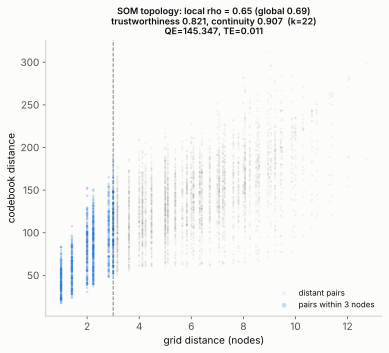

In [12]:
ab.pl.som_quality_plot(mdata, key='som_gene_modules').show()

### Is a module spatially organized?

Which module is most spatially interesting? Not the one whose score varies most across cells — that
statistic contains no coordinates at all, and is additionally biased toward *small* modules, since
averaging more genes reduces score variance. The question is spatial, so the statistic should be:
rank modules by **Moran's I** of their per-cell score on the spatial graph.

Because the score is background-corrected, a flat map means the module genuinely is spatially uniform
— not merely that its genes are abundant everywhere. A coherent territorial map means a co-regulated
program tied to tissue architecture.

C:\Users\Austin\PycharmProjects\astrolabe\.venv\Lib\site-packages\libpysal\weights\weights.py:1683: UserWarning: The weights matrix is not fully connected: 
 There are 7 disconnected components.
  w = W(neighbors, weights, ids, silence_warnings=silence_warnings)
INFO:astrolabe.tl._spatial_stats:moran: 9 keys, 154376 cells, n_perms=99


INFO:astrolabe.tl._spatial_stats:moran: done — top I=0.751 (module_M9)


                I  p_sim
key                     
module_M9  0.7512   0.01
module_M2  0.6583   0.01
module_M6  0.6400   0.01
module_M7  0.5576   0.01
module_M1  0.4255   0.01
module_M0  0.3789   0.01
module_M5  0.3177   0.01
module_M8  0.3036   0.01
module_M4  0.2993   0.01


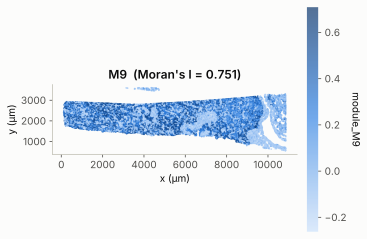

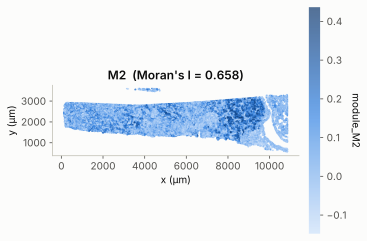

In [13]:
scores = xen.obsm['som_gene_modules_scores']
for j, m in enumerate(names):
    xen.obs[f'module_{m}'] = scores[:, j]

moran = ab.tl.moran(mdata, keys=[f'module_{m}' for m in names],
                    neighbors_key='spatial_neighbors', n_perms=99, seed=0)
moran = moran.sort_values('I', ascending=False)
print(moran[['I', 'p_sim']].round(4).to_string())

top_two = [i.replace('module_', '') for i in moran.index[:2]]
ab.pl.points(mdata, color=f'module_{top_two[0]}',
              title=f"{top_two[0]}  (Moran's I = {moran['I'].iloc[0]:.3f})"
              ).show()

# one map per cell: this section is a thin strip, and pairing two of them with
# either '|' or '/' letterboxes both into unreadable slivers
ab.pl.points(mdata, color=f'module_{top_two[1]}',
             title=f"{top_two[1]}  (Moran's I = {moran['I'].iloc[1]:.3f})"
             ).show()

## Summary

- `tl.som` — FlowSOM-style clustering: overclustered grid, Ward metaclusters as the reported labels.
  Judge the map with `pl.som_umatrix`, `pl.som_hits` and `pl.som_quality_plot` (whose headline
  topology statistic is **local**, because that is the claim map figures rely on) before believing
  anything it produces.
- `tl.som_stability` + `pl.som_stability_plot` — whether the cluster count survives a reseed, and
  whether the merge tree privileges it. Read the plateau.
- `tl.som(use_rep=None)` + `pl.som_component_plane` — per-gene landscapes across the map, FlowSOM's
  canonical identity readout. A separate map from the one you clustered with.
- `tl.som_gene_modules` — correlation-based gene programs with background-corrected per-cell scores.
  **Read `module_coherence` before the module list**; incoherent modules are labelled `unassigned`
  rather than reported, and `kme` ranks the hub genes. Cross-check against the spatial route in
  `06_trajectory_and_gene_modules.ipynb`.

**Where to go next:** `14_subcellular_localization.ipynb` for what the transcript positions inside
each cell can say; `02_spatial_statistics.ipynb` to test SOM clusters for spatial structure;
`03_neighborhood_analysis.ipynb` for neighbourhood enrichment between metaclusters;
`10_gradient_and_flux.ipynb` to measure directional structure in the module scores mapped above.